<a href="https://colab.research.google.com/github/BranMerx/Airbnb-Data-Analysis/blob/main/Airbnb_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Loading dataset
file_path = "/content/Airbnb_Open_Data.csv"
df = pd.read_csv(file_path)

#Displaying first few rows of the dataset
print(df.head())

        id                                              NAME      host id  \
0  1001254                Clean & quiet apt home by the park  80014485718   
1  1002102                             Skylit Midtown Castle  52335172823   
2  1002403               THE VILLAGE OF HARLEM....NEW YORK !  78829239556   
3  1002755                                               NaN  85098326012   
4  1003689  Entire Apt: Spacious Studio/Loft by central park  92037596077   

  host_identity_verified host name neighbourhood group neighbourhood  \
0            unconfirmed  Madaline            Brooklyn    Kensington   
1               verified     Jenna           Manhattan       Midtown   
2                    NaN     Elise           Manhattan        Harlem   
3            unconfirmed     Garry            Brooklyn  Clinton Hill   
4               verified    Lyndon           Manhattan   East Harlem   

        lat      long        country  ... service fee minimum nights  \
0  40.64749 -73.97237  United St

/tmp/ipykernel_1146/2974663273.py:7: DtypeWarning: Columns (25) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [3]:
df.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='object')

In [4]:
print(df.isnull().sum())

id                                    0
NAME                                182
host id                               0
host_identity_verified              217
host name                           245
neighbourhood group                  30
neighbourhood                        17
lat                                   9
long                                  9
country                              95
country code                         87
instant_bookable                     87
cancellation_policy                  58
room type                             1
Construction year                   185
price                               141
service fee                         141
minimum nights                      351
number of reviews                   152
last review                       10708
reviews per month                 10694
review rate number                  183
calculated host listings count      129
availability 365                    433
house_rules                       23380


In [5]:
#Handling Missing Values
# Convert 'last review' to datetime and handle errors
df['last review'] = pd.to_datetime(df['last review'], errors='coerce')

# Fill missing values
df.fillna({'reviews per month': 0, 'last review': df['last review'].min()}, inplace=True)

# Drop records with missing 'name' or 'host name'
df.dropna(subset=['NAME', 'host name'], inplace=True)

In [6]:
#Correcting data types
# Remove dollar signs and convert to float
df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)
df['service fee'] = df['service fee'].replace('[\$,]', '', regex=True).astype(float)

<>:3: SyntaxWarning: invalid escape sequence '\$'
<>:4: SyntaxWarning: invalid escape sequence '\$'
<>:3: SyntaxWarning: invalid escape sequence '\$'
<>:4: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_1146/1837909990.py:3: SyntaxWarning: invalid escape sequence '\$'
  df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)
/tmp/ipykernel_1146/1837909990.py:4: SyntaxWarning: invalid escape sequence '\$'
  df['service fee'] = df['service fee'].replace('[\$,]', '', regex=True).astype(float)


In [7]:
df.drop_duplicates(inplace=True)

In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 55553 entries, 0 to 55973
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              55553 non-null  int64         
 1   NAME                            55553 non-null  object        
 2   host id                         55553 non-null  int64         
 3   host_identity_verified          55349 non-null  object        
 4   host name                       55553 non-null  object        
 5   neighbourhood group             55526 non-null  object        
 6   neighbourhood                   55536 non-null  object        
 7   lat                             55544 non-null  float64       
 8   long                            55544 non-null  float64       
 9   country                         55464 non-null  object        
 10  country code                    55475 non-null  object        
 11  instant

In [9]:
#Descriptive statistics
print(df.describe())
#Generates stats that summarize the central tendency,
#dispersion, and shape of a dataset's distribution, excluding NaN values


                 id       host id           lat          long  \
count  5.555300e+04  5.555300e+04  55544.000000  55544.000000   
mean   1.647222e+07  4.936691e+10     40.728295    -73.950458   
min    1.001254e+06  1.303496e+08     40.499790    -74.249840   
25%    8.722490e+06  2.473036e+10     40.689150    -73.983030   
50%    1.651158e+07  4.923892e+10     40.722540    -73.954980   
75%    2.421009e+07  7.410418e+10     40.762730    -73.933400   
max    3.191522e+07  9.876266e+10     40.916850    -73.705220   
std    8.930351e+06  2.850070e+10      0.055114      0.048623   

       Construction year         price   service fee  minimum nights  \
count       55382.000000  55415.000000  55412.000000    55208.000000   
mean         2012.490304    623.926662    124.738089        7.151282   
min          2003.000000     50.000000     10.000000    -1223.000000   
25%          2008.000000    336.000000     67.000000        1.000000   
50%          2012.000000    623.000000    125.000000  

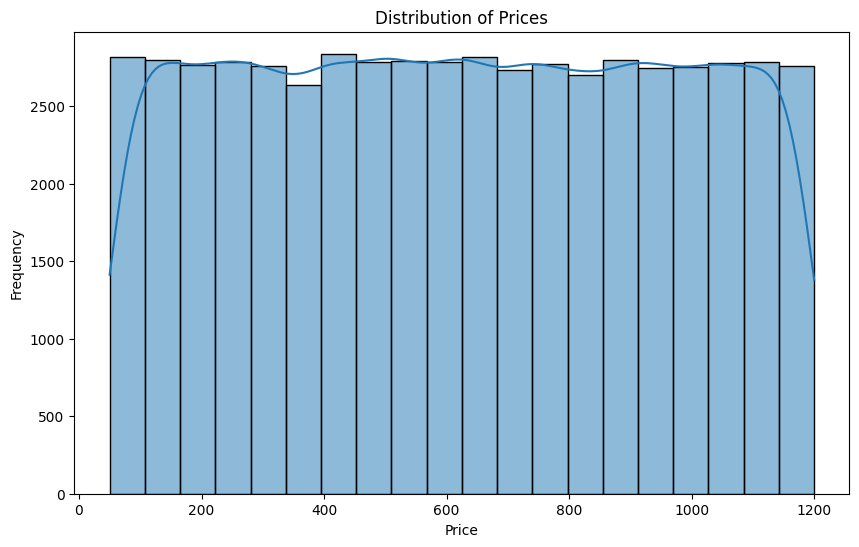

In [10]:
#Visualization
plt.figure(figsize=(10,6))
sns.histplot(df['price'], bins=20, kde=True)
plt.title('Distribution of Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()
#Plotting the distribution of listing prices

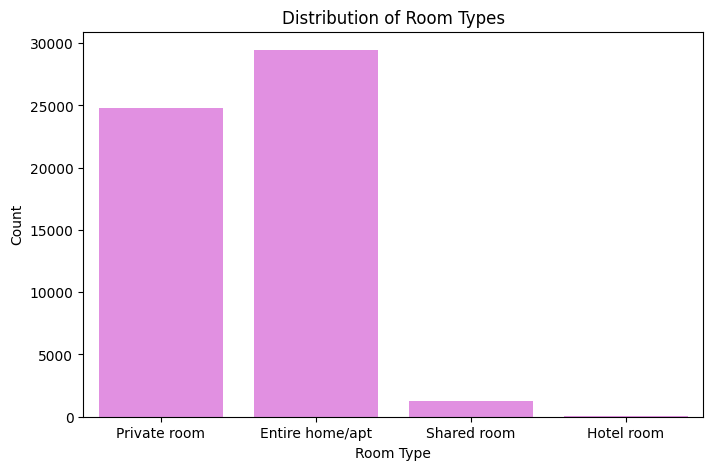

In [11]:
#Analyzing distribution of different room types
plt.figure(figsize=(8,5))
sns.countplot(x='room type', data=df, color='violet')
plt.title('Distribution of Room Types')
plt.xlabel('Room Type')
plt.ylabel('Count')
plt.show()
#

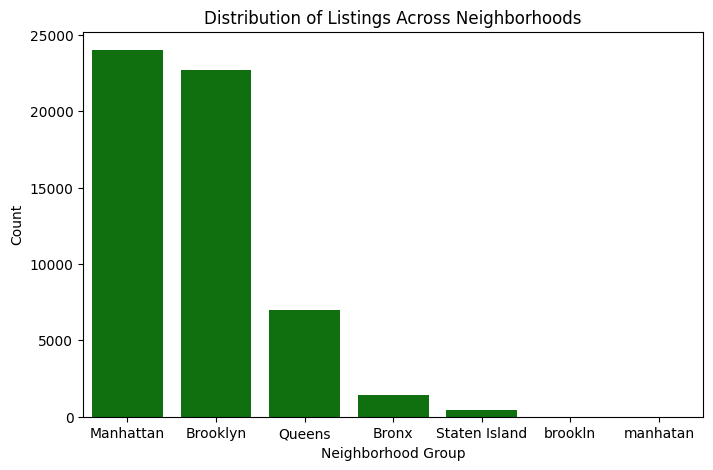

In [18]:
#Examination on how listings are distrbuted across different neighborhoods
plt.figure(figsize=(8,5))
sns.countplot(x='neighbourhood group', data=df, color='green',
order=df['neighbourhood group'].value_counts().index)
plt.title('Distribution of Listings Across Neighborhoods')
plt.xlabel('Neighborhood Group')
plt.ylabel('Count')
plt.show()

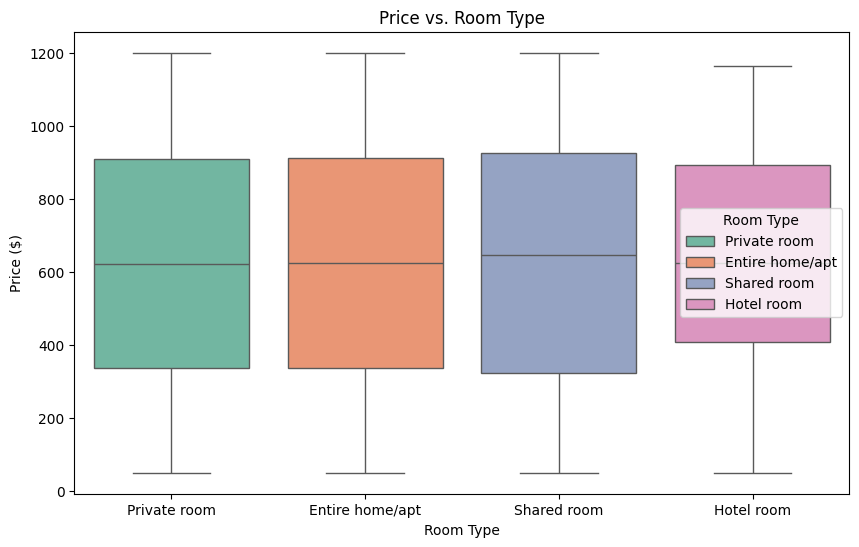

In [20]:
#Visual of the relationship between price and room type
plt.figure(figsize=(10,6))
sns.boxplot(x='room type', y = 'price', hue ='room type', data=df,
palette='Set2')
plt.title('Price vs. Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price ($)')
plt.legend(title='Room Type')
plt.show()
#

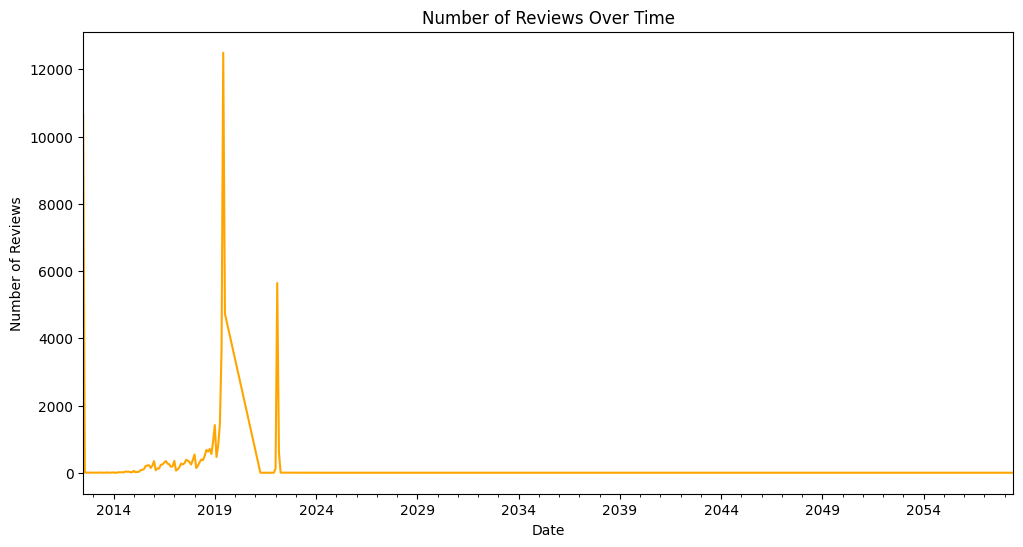

In [25]:
#Reviews over time
df['last review'] = pd.to_datetime(df['last review'])
reviews_over_time = df.groupby(df['last review'].dt.to_period('M')).size()

plt.figure(figsize=(12, 6))
reviews_over_time.plot(kind='line',color='Orange')
plt.title('Number of Reviews Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')
plt.show()